<a href="https://colab.research.google.com/github/VitorVianaGS/Colab_ad05/blob/main/Desafio2_Estatistica_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Célula 01 Importar Dependências**

In [1]:
# ---------- Bibliotecas: ferramentas prontas que o Python usa ----------
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

# Estas linhas servem para trabalhar no Google Colab (conectar ao Drive e enviar arquivos)
from google.colab import drive     # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import files     # (files) envia arquivos do seu computador para o Colab

# Bibliotecas de análise de dados e de gráficos
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

# ---------- Configurações gerais (valem para todos os gráficos abaixo) ----------
warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (8, 6)    # tamanho padrão dos gráficos (largura, altura)

**Célula 02 Carregar Dados**

In [2]:
# Nomes das tabelas do seu tema (veja a tabela acima), iguais aos nomes dos arquivos CSV.
NOME_TABELA_DIMENSAO = "clientes"   # ex.: "clientes"
NOME_TABELA_FATO = "chamados"       # ex.: "chamados"

# ---------- 1) Conectando ao Google Drive ----------
drive.mount("/content/drive")      # vai pedir autorização na primeira vez

# ---------- 2) Dizendo onde os arquivos estão guardados ----------
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/desafios/dados")   # pasta onde a base fica guardada no Drive
pasta_dados.mkdir(parents=True, exist_ok=True)                                # cria a pasta "dados" se faltar

# O "/" junta a pasta com o nome do arquivo (o nome vem da variável de cada tabela).
caminho_dimensao = pasta_dados / f"{NOME_TABELA_DIMENSAO}.csv"
caminho_fato = pasta_dados / f"{NOME_TABELA_FATO}.csv"

# ---------- 3) Se faltar algum arquivo, envia os dois de uma vez e o código separa ----------
if not caminho_dimensao.exists() or not caminho_fato.exists():
    print(f"Selecione os arquivos CSV ({NOME_TABELA_DIMENSAO} e {NOME_TABELA_FATO}). Pode escolher os dois de uma vez:")
    enviados = files.upload()                                  # abre o seletor; aceita vários arquivos

    for nome_enviado in enviados:                              # percorre cada arquivo enviado
        if NOME_TABELA_DIMENSAO in nome_enviado.lower():       # o nome contém o da dimensão? salva como dimensão
            shutil.move(nome_enviado, caminho_dimensao)        # salva já com o nome da tabela
            print(f"{nome_enviado} -> {caminho_dimensao.name}")
        elif NOME_TABELA_FATO in nome_enviado.lower():         # o nome contém o da fato? salva como fato
            shutil.move(nome_enviado, caminho_fato)
            print(f"{nome_enviado} -> {caminho_fato.name}")
        else:                                                  # nome que não combina com nenhuma tabela
            print(f"Ignorado: {nome_enviado} (o nome não contém '{NOME_TABELA_DIMENSAO}' nem '{NOME_TABELA_FATO}')")

# Confere se os dois arquivos estão no Drive antes de ler.
for caminho in [caminho_dimensao, caminho_fato]:
    if not caminho.exists():
        raise FileNotFoundError(f"Falta o arquivo {caminho.name}. Execute a célula de novo e envie-o.")

# ---------- 4) Lendo os dois arquivos ----------
df_dimensao = pd.read_csv(caminho_dimensao)
df_fato = pd.read_csv(caminho_fato)

print(NOME_TABELA_DIMENSAO, "->", len(df_dimensao), "linhas")
print(NOME_TABELA_FATO, "->", len(df_fato), "linhas")

Mounted at /content/drive
clientes -> 10400 linhas
chamados -> 42000 linhas


**Célula 03 Conhecendo a tabela Dimensao**

In [3]:
# Quantas linhas (registros do cadastro) e colunas (variáveis) tem a tabela dimensão?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_dimensao.shape
print(f"A tabela dimensão tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_dimensao.head())

A tabela dimensão tem 10400 linhas e 4 colunas (variáveis)


,cliente_id,segmento,canal_preferido,data_cadastro
0,1,pequena_empresa,chat,2019-03-01
1,2,pessoa_fisica,chat,2024-04-22
2,3,pessoa_fisica,telefone,2026-05-04
3,4,pequena_empresa,telefone,2025-06-09
4,5,pessoa_fisica,email,2025-06-28


**Célula 04 Conhecendo a tabela Fato**

In [4]:
# Quantas linhas (eventos) e colunas (variáveis) tem a tabela fato?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_fato.shape
print(f"A tabela fato tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_fato.head())

A tabela fato tem 42000 linhas e 8 colunas (variáveis)


,chamado_id,cliente_id,data_hora_abertura,canal,motivo,tempo_atendimento_min,nota_satisfacao,resolvido_primeiro_contato
0,1,1180,2026-05-08 06:25:57,chat,solicitacao_tecnica,17,2,False
1,2,5899,2026-05-21 11:21:58,telefone,duvida,21,2,False
2,3,195,2025-03-16 18:37:14,telefone,reclamacao,43,3,False
3,4,3216,2025-04-09 02:17:26,presencial,solicitacao_tecnica,13,5,True
4,5,5598,2026-07-05 18:46:00,chat,elogio,15,3,True


### Pergunta que eu quero responder:

Como se comporta o tempo de atendimento dos chamados, o que explica a sua variação e como podemos melhorar a eficiência da operação e a satisfação dos clientes?

**Célula 05 Tipos das colunas**

In [5]:
# 1) Tipo de cada coluna e quantidade de valores preenchidos. Compare com o esquema do plano do tema.
df_fato.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Data columns (total 8 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   chamado_id                  42000 non-null  int64 
 1   cliente_id                  42000 non-null  int64 
 2   data_hora_abertura          42000 non-null  object
 3   canal                       42000 non-null  object
 4   motivo                      42000 non-null  object
 5   tempo_atendimento_min       42000 non-null  int64 
 6   nota_satisfacao             42000 non-null  int64 
 7   resolvido_primeiro_contato  42000 non-null  bool  
dtypes: bool(1), int64(4), object(3)
memory usage: 2.3+ MB


**Célula 06 Valores ausentes**

In [6]:
# 2) Valores ausentes por coluna (tabela fato).
print("\nValores ausentes por coluna:")
print(df_fato.isna().sum())


Valores ausentes por coluna:
chamado_id                    0
cliente_id                    0
data_hora_abertura            0
canal                         0
motivo                        0
tempo_atendimento_min         0
nota_satisfacao               0
resolvido_primeiro_contato    0
dtype: int64


**Célula 07 Linhas duplicadas**

In [7]:
# 3) Linhas duplicadas (tabela fato).
print("\nLinhas duplicadas:", df_fato.duplicated().sum())


Linhas duplicadas: 0


**Célula 08 Chave estrangeira**

In [8]:
# 4) Chave estrangeira: todos os registros da tabela fato devem apontar para um ID que existe na tabela dimensão.
COLUNA_FK = "cliente_id"   # ex.: "livro_id" (coluna da fato que referencia a dimensão)
COLUNA_ID = "cliente_id"   # ex.: "livro_id" (coluna de ID da dimensão)
print("\nChaves estrangeiras que batem:", df_fato[COLUNA_FK].isin(df_dimensao[COLUNA_ID]).all())


Chaves estrangeiras que batem: True


In [9]:
registro = df_dimensao.loc[df_dimensao["cliente_id"] == 4502]
print(registro)

      cliente_id       segmento canal_preferido data_cadastro
4501        4502  pessoa_fisica      presencial    2022-07-03


**Célula 09 · Checar a coluna numérica**

In [10]:
# Coluna numérica escolhida no Passo 1 (nome EXATO, como está no esquema do tema).
COLUNA_NUMERICA = "tempo_atendimento_min"

# A coluna escolhida, como uma série (uma coluna do DataFrame).
serie_numerica = df_fato[COLUNA_NUMERICA]
print("Valores preenchidos:", serie_numerica.count(), "| ausentes:", serie_numerica.isna().sum())

Valores preenchidos: 42000 | ausentes: 0


**Célula 10 Medidas estatísticas**

In [11]:
# Medidas de Tendência central e dispersão.
medidas = pd.Series({
    "Média": serie_numerica.mean(),
    "Mediana": serie_numerica.median(),
    "Moda": serie_numerica.mode()[0],            # se houver empate, a primeira será selecionada
    "Desvio padrão": serie_numerica.std(),
    "Variância": serie_numerica.var(),
    "Mínimo": serie_numerica.min(),
    "Máximo": serie_numerica.max(),
    "Amplitude": serie_numerica.max() - serie_numerica.min(),
}).round(2)
display(medidas)

# Média muito diferente da mediana é sinal de valores extremos ou de dados assimétricos.
print("Média - mediana:", round(medidas["Média"] - medidas["Mediana"], 2))

,0
Média,15.60
Mediana,13.00
Moda,9.00
Desvio padrão,11.28
Variância,127.24
Mínimo,1.00
Máximo,107.00
Amplitude,106.00


Média - mediana: 2.6


- **A média da coluna tempo_atendimento_min é 15.60 min. Representa o tempo médio de atendimento, serve coma base inicial para as análises.

- **A mediana de tempo_atendimento_min é 13,00 minutos. Como a média está 2,60 minutos acima da mediana, Fica claro que os dados são assimétricos e existem chamados muito longos chegando ao máximo de 107 minutos puxando a média para cima.

- **O desvio padrão de 11,28 minutos — valor próximo à própria mediana (13,00 min) — evidencia uma alta dispersão e baixa previsibilidade no tempo de atendimento. Na prática, isso indica falta de padronização no fluxo, alternando entre resoluções muito rápidas e chamados excessivamente longos.

- **Decisão final:** (escreva uma frase com a decisão que as três medidas apoiam.)

Os atendimentos duram o mesmo tempo em todos os chamdos ou alguns duram mais, se sim porque?

**Célula 11 · Juntar a fato com a dimensão**

In [12]:
# Junta a fato com a dimensão: cada registro da fato recebe as colunas do seu cadastro.
df_completo = df_fato.merge(df_dimensao, left_on=COLUNA_FK, right_on=COLUNA_ID, how="left", suffixes=("", "_dim"))

print("Linhas da fato:", len(df_fato), "| depois da junção:", len(df_completo))   # precisam ser iguais

Linhas da fato: 42000 | depois da junção: 42000


Célula 12 · Comparar grupos por uma coluna da fato

In [13]:
# Coluna categórica usada para comparar (da fato ou da dimensão). Poucos valores diferentes funcionam melhor.
COLUNA_GRUPO = "motivo"

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
motivo,,,,
elogio,2120,15.85,13.0,11.33
solicitacao_tecnica,10389,15.69,13.0,11.42
reclamacao,10511,15.65,13.0,11.35
duvida,14736,15.54,13.0,11.25
cancelamento,4244,15.37,13.0,10.85


**Leitura por (coluna de grupo)**

- (O motivo elogio tem a maior média (15,85 min), mas a mediana de 13,0 min é idêntica em todos os grupos, mostrando que o tempo típico é igual e a diferença vem de poucos casos atípicos.)
- (O grupo solicitacao_tecnica apresenta a maior variação (11,42 min), indicando tempos mais espalhados e imprevisíveis nesse tipo de chamado.)
- (Como as médias ficam todas entre 15,37 e 15,85 minutos, o motivo do contato não é o que faz um atendimento demorar mais ou menos.)

**Célula 13 · Comparar grupos por uma coluna da dimensão**

In [14]:
COLUNA_GRUPO = "resolvido_primeiro_contato"     # coluna da dimensão: só existe em df_completo por causa da junção

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
resolvido_primeiro_contato,,,,
False,19684,23.46,22.0,11.59
True,22316,8.67,9.0,4.28


Analizando por segmento: mostra que a maioria da carga de operação é por pessoa_fisica, cerca de 75% dos chamados

Por resolvido_primeiro_contato a média cai para 8.67 e a mediana cai para 9.0 abaixando o desvio padrão para 4.28, o que se deduz um atendimento mais rápido e padrão.

Quando não é resolvido a média dispara para 23.46 a mediana sobe para 22.0 aumentando o desvio padrão para 11.59 acumulando maior variação e casos mais longos

**Célula 14 · Regra do IQR**

In [15]:
# Faixa central dos dados: do 1º ao 3º quartil (25% e 75%).
q1 = serie_numerica.quantile(0.25)
q3 = serie_numerica.quantile(0.75)
iqr = q3 - q1

# Regra usual: fora de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR] é candidato a outlier.
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Cálculo do número de outliers
sem_outliers = serie_numerica[(serie_numerica >= limite_inferior) & (serie_numerica <= limite_superior)]
qtd_outliers = serie_numerica.count() - sem_outliers.count()

print(f"Limites: {limite_inferior:.2f} a {limite_superior:.2f}")
print(f"Outliers: {qtd_outliers} de {serie_numerica.count()} valores")
print("Maiores valores:", serie_numerica.nlargest(5).tolist())
print("Menores valores:", serie_numerica.nsmallest(5).tolist())

Limites: -14.00 a 42.00
Outliers: 1247 de 42000 valores
Maiores valores: [107, 96, 96, 95, 93]
Menores valores: [1, 1, 1, 1, 1]


Limites e quantidade: A faixa normal vai até 42,00 minutos, identificando 1.247 outliers em 42.000 registros (cerca de 2,97%), com picos entre 93 e 107 minutos.   Decisão: Os valores devem ser mantidos na base por representarem atendimentos complexos reais (especialmente sem resolução no primeiro contato) e não erros de sistema, usando a mediana (13 min) como referência para não distorcer as metas.  

Célula 15 · Medidas com e sem os candidatos a outlier

In [16]:
# Compara as medidas com e sem os candidatos a outlier.
comparacao = pd.DataFrame({
    "Com outliers": [serie_numerica.mean(), serie_numerica.median(), serie_numerica.std()],
    "Sem outliers": [sem_outliers.mean(), sem_outliers.median(), sem_outliers.std()],
}, index=["Média", "Mediana", "Desvio padrão"]).round(2)
display(comparacao)

,Com outliers,Sem outliers
Média,15.60,14.50
Mediana,13.00,13.00
Desvio padrão,11.28,9.38


Apenas confirma o que foi dito acima, e é visivel que independente do outliers a mediana de mantém.

Célula 16 · Assimetria (skew)

In [17]:
# Assimetria: perto de 0 = formato equilibrado; positiva = cauda para valores altos; negativa = para valores baixos.
print("Assimetria:", round(serie_numerica.skew(), 2))

Assimetria: 1.39


A skell indica uma assimetria forte positiva (cauda para valores altos)

**Célula 17 · Percentis**

In [18]:
# Percentis: por exemplo, 50% dos valores ficam na mediana ou abaixo dela.
print(serie_numerica.quantile([0.10, 0.25, 0.50, 0.75, 0.90]))

0.10     4.0
0.25     7.0
0.50    13.0
0.75    21.0
0.90    31.0
Name: tempo_atendimento_min, dtype: float64


A distribuição dos percentis mostra que 25% dos chamados são resolvidos em até 7 minutos, 50% em até 13 minutos e 75% em até 21 minutos. Além disso, 90% de todos os atendimentos terminam em até 31 minutos, evidenciando que a grande maioria da operação ocorre de forma ágil e que os tempos muito elevados (acima de 31 minutos, chegando a 107 minutos) representam apenas os 10% mais demorados da base.

**Célula 18 · Quantidade de valores por faixa**

In [19]:
# Quantidade de valores em 5 faixas de mesmo tamanho (a versão em texto de um histograma).
display(pd.cut(serie_numerica, bins=5).value_counts().sort_index())

,count
tempo_atendimento_min,
"(0.894, 22.2]",32710
"(22.2, 43.4]",8169
"(43.4, 64.6]",1018
"(64.6, 85.8]",92
"(85.8, 107.0]",11


A divisão em 5 faixas de igual largura mostra que 32.710 dos 42.000 atendimentos (quase 78%) se concentram na primeira faixa, entre 1 e 22,2 minutos, seguidos por 8.169 chamados entre 22,2 e 43,4 minutos. A partir de 43,4 minutos a frequência cai drasticamente (1.018 casos até 64,6 min, 92 até 85,8 min e apenas 11 até 107 min), confirmando visualmente a assimetria positiva dos dados, com grande concentração nos tempos baixos e uma cauda longa de poucos casos extremos.


👣Passo 10 — Redigir a recomendação de decisão

## Recomendação

**Pergunta de negócio:** O que explica a variação no tempo de atendimento e como podemos tornar a operação mais ágil e satisfatória?

**Evidência 1:** O tempo típico de atendimento é de **13 minutos** (mediana), mas a média sobe para **15,6 minutos** e o desvio padrão chega a **11,28 minutos** (assimetria de **1,39**). Isso mostra que, embora 90% dos chamados terminem em até 31 minutos, uma pequena parcela de casos muito longos (até 107 minutos) puxa a média para cima e gera instabilidade na operação.

**Evidência 2:** Chamados resolvidos no primeiro contato levam em média **8,67 minutos** (mediana de **9 min**), enquanto os que não são resolvidos de primeira saltam para **23,46 minutos** (mediana de **22 min**) — quase o triplo do tempo —, o que derruba diretamente a nota de satisfação dos clientes (de quase 23 minutos nas notas 1 e 2 para menos de 9 minutos na nota 5).

**Recomendação em uma frase:** Para reduzir o tempo de atendimento e aumentar a satisfação dos clientes, a empresa deve investir em treinamento e ferramentas de suporte que permitam resolver mais problemas logo no primeiro contato.

**Limites da análise:** Não havia valores ausentes nos 42.000 registros analisados, e os 1.247 outliers (chamados acima de 42 minutos) foram mantidos por representarem gargalos reais da operação, usando a mediana como referência principal para não distorcer as metas.

Célula 19 · Histograma

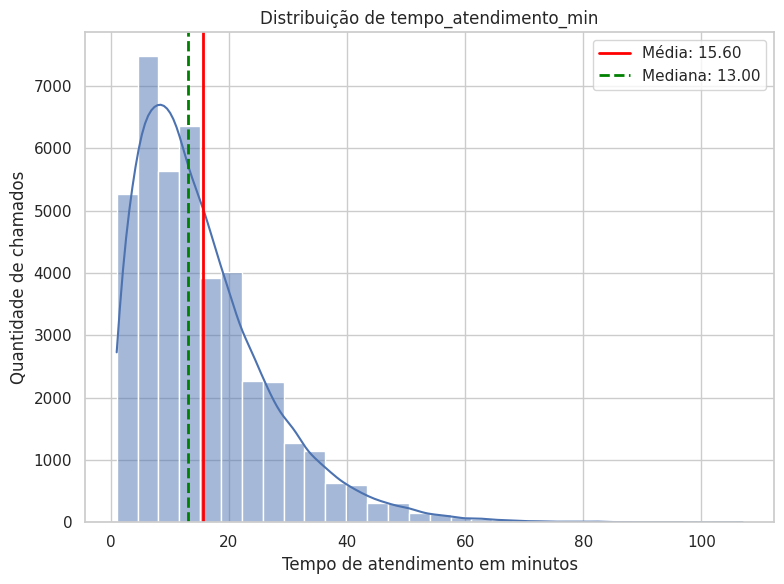

In [22]:
# Histograma: como os valores se distribuem, com a curva da distribuição e as linhas de média e mediana.
sns.histplot(serie_numerica.dropna(), bins=30, kde=True)
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.axvline(serie_numerica.median(), color="green", linestyle="--", linewidth=2, label=f"Mediana: {serie_numerica.median():.2f}")
plt.title(f"Distribuição de {COLUNA_NUMERICA}")
plt.xlabel("Tempo de atendimento em minutos")        # lacuna: nome do eixo x, em linguagem simples
plt.ylabel("Quantidade de chamados")            # lacuna: nome do eixo y, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

Analisei o histograma da distribuição do tempo de atendimento e notei uma assimetria positiva clara: a grande maioria dos chamados concentra-se nos primeiros minutos (com pico próximo da mediana de 13,00 minutos), enquanto uma cauda longa de casos mais demorados estende-se para a direita até ultrapassar os 100 minutos, puxando a média para 15,60 minutos.

**Célula 20 · Boxplot**

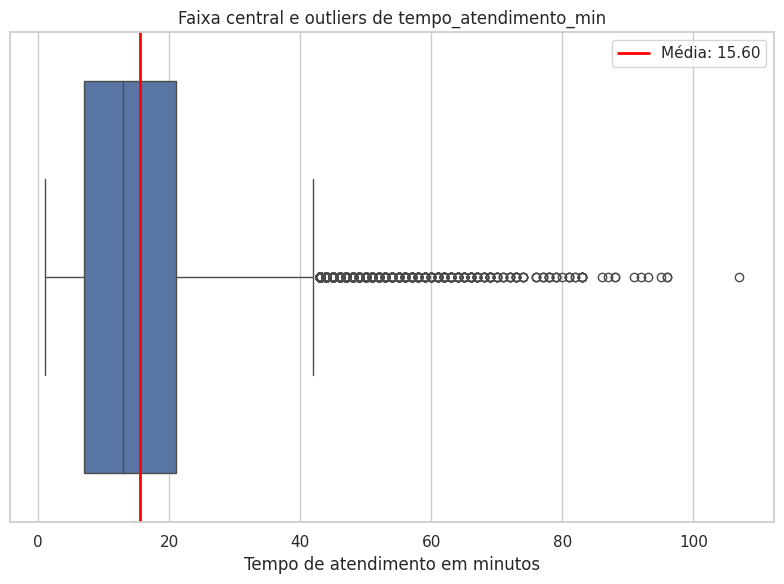

In [24]:
# Boxplot: a caixa é a faixa central (25% a 75%); os pontos fora são candidatos a outlier.
sns.boxplot(x=serie_numerica.dropna())
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.title(f"Faixa central e outliers de {COLUNA_NUMERICA}")
plt.xlabel("Tempo de atendimento em minutos")        # lacuna: nome do eixo x, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

**Registrar o uso de IA**

# Generated-by: AI (Gemini)
# AI-Generated-Date: 2026-11-17
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT